In [36]:
import pandas as pd
import numpy as np
import tensorflow as tf

In [37]:
import tensorflow as tf
tf.keras.mixed_precision.set_global_policy('mixed_float16')

In [38]:
df = pd.read_csv("data/02_B_longum_CAZyme_Overview.tsv", sep="\t")
df.head()
df.columns

Index(['Gene ID', 'EC#', 'dbCAN_hmm', 'dbCAN_sub', 'DIAMOND', '#ofTools',
       'Recommend Results', 'Substrate'],
      dtype='str')

df = df[df["Recommend Results"] != "-"]

X = df.drop(["Gene ID", "EC#", "Recommend Results"], axis=1)
y = df["Recommend Results"]

X = X.replace("-", "missing")
print(len(df))  # to check table presence

In [39]:
# --- Create simplified labels ---
def simplify_label(label):
    if label == "-" or pd.isna(label):
        return "unknown"
    return label.split("_")[0]

df["Simple_Class"] = df["Recommend Results"].apply(simplify_label)

# Remove unknowns
df = df[df["Simple_Class"] != "unknown"]

# --- Recreate X and y ---
X = df.drop(["Gene ID", "EC#", "Recommend Results", "Simple_Class"], axis=1)
y = df["Simple_Class"]

# --- Replace missing values ---
X = X.replace("-", "missing")

# --- Encode EVERYTHING ---
from sklearn.preprocessing import LabelEncoder

for col in X.columns:
    X[col] = LabelEncoder().fit_transform(X[col])

y = LabelEncoder().fit_transform(y)

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.33)
print(X_train.shape)
print(X_val.shape)
print(X_test.shape) # to check no empty sets

(108, 5)
(31, 5)
(16, 5)


In [41]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(len(set(y)), activation='softmax')
])

In [42]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [43]:
tf.debugging.set_log_device_placement(True)

In [44]:
print(X.dtypes)

dbCAN_hmm    int64
dbCAN_sub    int64
DIAMOND      int64
#ofTools     int64
Substrate    int64
dtype: object


In [45]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20
)

Epoch 1/20


I0000 00:00:1776241610.190371    1422 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5126__.27
I0000 00:00:1776241610.487179    1422 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


1/4 ━━━━━━━━━━━━━━━━━━━━ 17s 6s/step - accuracy: 0.0000e+00 - loss: 14.3216

I0000 00:00:1776241614.814586    1421 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5126__.27


4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.0556 - loss: 13.3587 - val_accuracy: 0.1613 - val_loss: 12.7107
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0833 - loss: 13.5341 - val_accuracy: 0.1613 - val_loss: 12.7107
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.0926 - loss: 13.0281 - val_accuracy: 0.1613 - val_loss: 12.8146
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0556 - loss: 13.0007 - val_accuracy: 0.1613 - val_loss: 12.9098
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1111 - loss: 12.4871 - val_accuracy: 0.1613 - val_loss: 12.9608
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.0833 - loss: 12.6293 - val_accuracy: 0.1613 - val_loss: 13.0115
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1111 - loss: 12.6887 - val_accuracy: 0.1613 - val_loss: 12.9276
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1204 - loss: 12.4233 - val_accuracy: 0.1613 - val_loss: 12.5

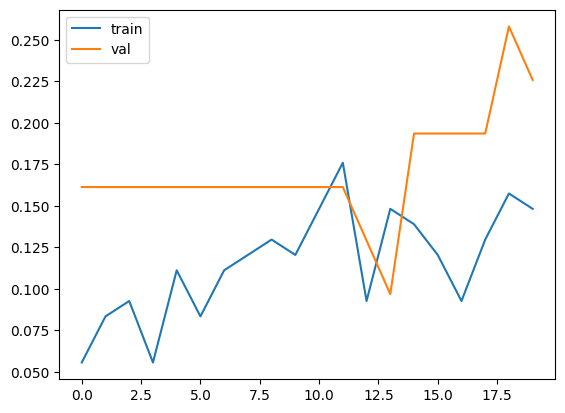

In [46]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.show()

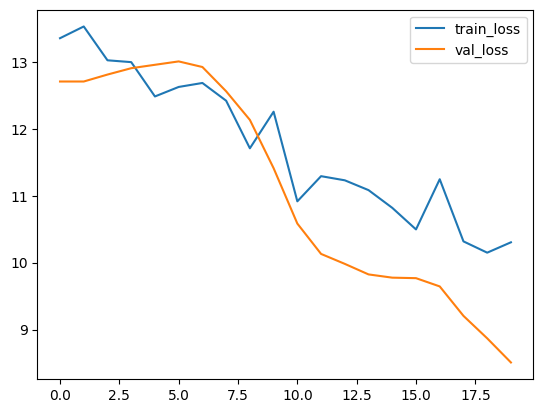

In [47]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 554ms/step


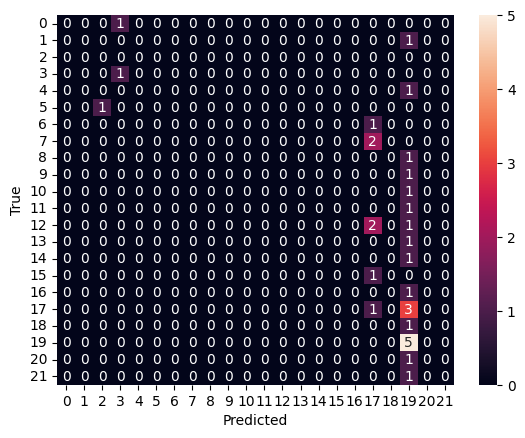

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

y_pred = model.predict(X_val)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_val, y_pred_classes)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [49]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred_classes))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.00      0.00      0.00         1
           2       0.00      0.00      0.00         0
           4       0.50      1.00      0.67         1
           7       0.00      0.00      0.00         1
          11       0.00      0.00      0.00         1
          12       0.00      0.00      0.00         1
          15       0.00      0.00      0.00         2
          17       0.00      0.00      0.00         1
          19       0.00      0.00      0.00         1
          21       0.00      0.00      0.00         1
          23       0.00      0.00      0.00         1
          30       0.00      0.00      0.00         3
          32       0.00      0.00      0.00         1
          36       0.00      0.00      0.00         1
          37       0.00      0.00      0.00         1
          39       0.00      0.00      0.00         1
          44       0.14    

/home/lohen/projects/ml/Machine learning/tf-env311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lohen/projects/ml/Machine learning/tf-env311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lohen/projects/ml/Machine learning/tf-env311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  

In [50]:
print(history.history)

print("Final train acc:", history.history['accuracy'][-1])
print("Final val acc:", history.history['val_accuracy'][-1])
print("Final train loss:", history.history['loss'][-1])
print("Final val loss:", history.history['val_loss'][-1])

print("Classes:", len(set(y)))

print(X_train.shape, X_val.shape, X_test.shape)

{'accuracy': [0.0555555559694767, 0.0833333358168602, 0.09259258955717087, 0.0555555559694767, 0.1111111119389534, 0.0833333358168602, 0.1111111119389534, 0.12037037312984467, 0.12962962687015533, 0.12037037312984467, 0.14814814925193787, 0.17592592537403107, 0.09259258955717087, 0.14814814925193787, 0.1388888955116272, 0.12037037312984467, 0.09259258955717087, 0.12962962687015533, 0.15740740299224854, 0.14814814925193787], 'loss': [13.35866928100586, 13.534107208251953, 13.028053283691406, 13.000654220581055, 12.487137794494629, 12.629290580749512, 12.688714981079102, 12.423271179199219, 11.711345672607422, 12.258977890014648, 10.917864799499512, 11.294251441955566, 11.23237419128418, 11.085461616516113, 10.82030200958252, 10.497434616088867, 11.248431205749512, 10.318525314331055, 10.149726867675781, 10.304818153381348], 'val_accuracy': [0.16129031777381897, 0.16129031777381897, 0.16129031777381897, 0.16129031777381897, 0.16129031777381897, 0.16129031777381897, 0.16129031777381897, 0

In [51]:
from sklearn.metrics import classification_report
pred = model.predict(X_test)
pred_classes = pred.argmax(axis=1)

print(classification_report(y_test, pred_classes))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 852ms/step
              precision    recall  f1-score   support

           2       0.00      0.00      0.00         0
           4       0.00      0.00      0.00         0
           6       0.00      0.00      0.00         1
           8       0.00      0.00      0.00         1
          10       0.00      0.00      0.00         1
          11       0.00      0.00      0.00         2
          17       0.00      0.00      0.00         1
          35       0.00      0.00      0.00         1
          41       0.00      0.00      0.00         1
          44       0.00      0.00      0.00         1
          47       0.00      0.00      0.00         1
          51       0.17      1.00      0.29         2
          53       0.00      0.00      0.00         2
          54       0.00      0.00      0.00         1
          57       0.00      0.00      0.00         1

    accuracy                           0.12        16
   macro avg       0.01      0.07      0.

/home/lohen/projects/ml/Machine learning/tf-env311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lohen/projects/ml/Machine learning/tf-env311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lohen/projects/ml/Machine learning/tf-env311/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  